# ChurnMind AI – Intelligent Customer Analytics Agent

## Project Overview

This project predicts whether a telecom customer is likely to leave the company using Machine Learning. It also analyzes customer data and provides business insights through visualizations and an AI dashboard.

## Import and Install Required Libraries

In [3]:
import sys
import subprocess

packages = [
    "pandas",
    "numpy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "plotly",
    "joblib",
    "streamlit"
]

for package in packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])

print("All required libraries are installed successfully.")

All required libraries are installed successfully.


## Import Libraries

Import all the required Python libraries for data analysis, visualization, and machine learning.

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import joblib

## Load Dataset

Load the IBM Telco Customer Churn dataset into a Pandas DataFrame.

In [2]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Display Dataset

In [3]:
df.head

<bound method NDFrame.head of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL   

## Display Dataset Information

This step displays the structure of the dataset, including column names, data types, and missing values.

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Check Dataset Size

Display the total number of rows and columns.

In [12]:
print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


## Display Column Names

View all column names available in the dataset.

In [13]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Statistical Summary

Generate summary statistics for numerical columns.

In [14]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## Check Missing Values

Identify missing values in each column.

In [17]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Check Duplicate Records

Find duplicate rows in the dataset.

In [16]:
df.duplicated().sum()

np.int64(0)

## Remove Duplicate Records

Remove duplicate rows if any are found.

In [18]:
df = df.drop_duplicates()
print("Updated Shape:", df.shape)

Updated Shape: (7043, 21)


## Data Cleaning

Convert the TotalCharges column into numeric format because it may contain text values.

In [19]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

## Handle Missing Values

Replace missing values with the median value.

In [6]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

## Verify Data Types

Check the updated data types after cleaning.

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand customer behaviour, identify hidden patterns, analyze relationships between different features, and discover important factors responsible for customer churn.

Data visualization techniques are used to generate meaningful business insights from the customer dataset.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

## Churn Distribution Analysis

This analysis represents the distribution of customers who stayed with the company and customers who left the service.

It helps in understanding the overall customer churn rate in the dataset.

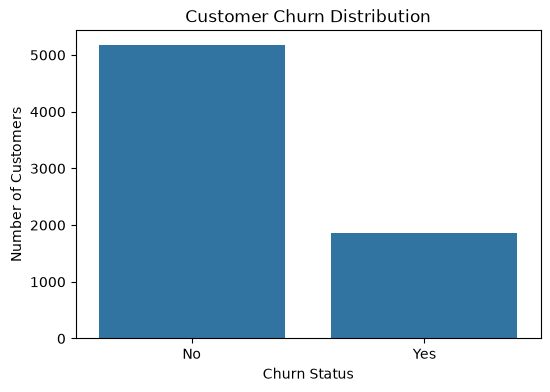

In [8]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

## Numerical Feature Distribution Analysis

This section analyzes numerical features such as tenure, monthly charges, and total charges.

The visualization helps understand customer behaviour patterns and feature distribution.

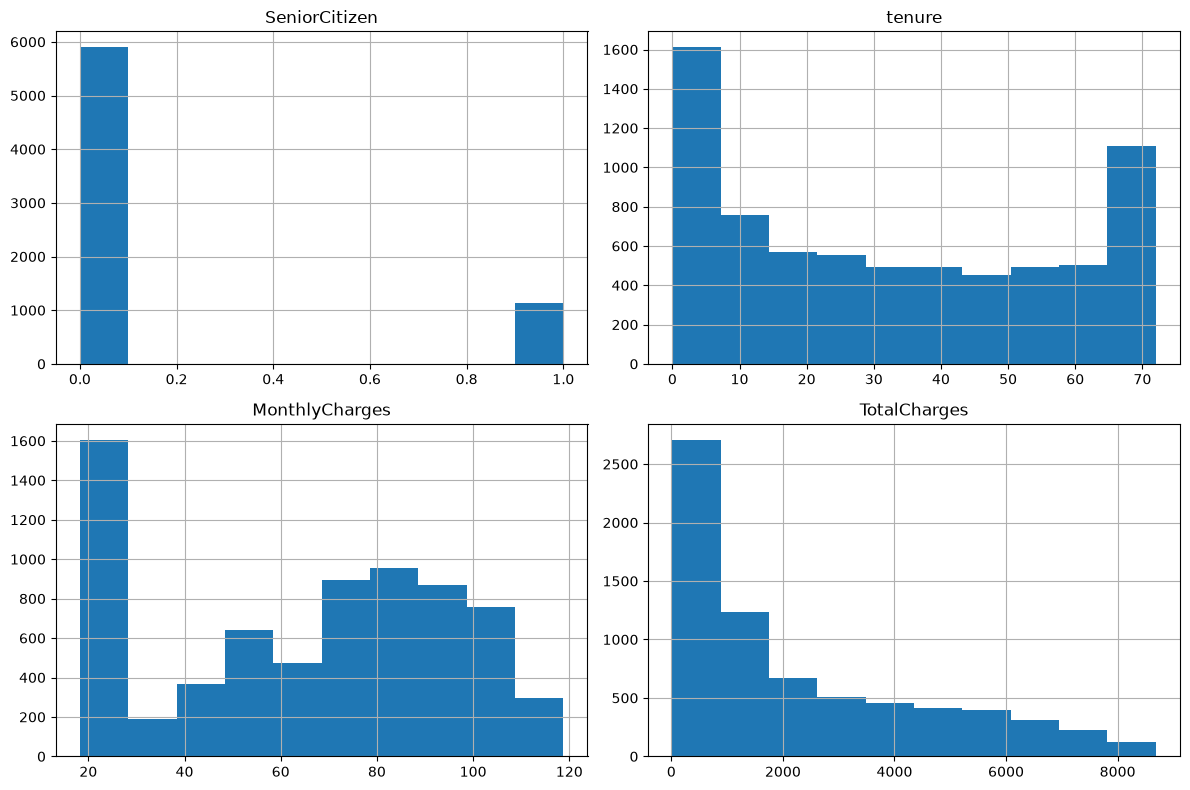

In [9]:
df.hist(figsize=(12,8))

plt.tight_layout()

plt.show()

## Contract Type Analysis

Contract type is an important factor affecting customer retention.

This visualization analyzes churn behaviour among different contract categories.

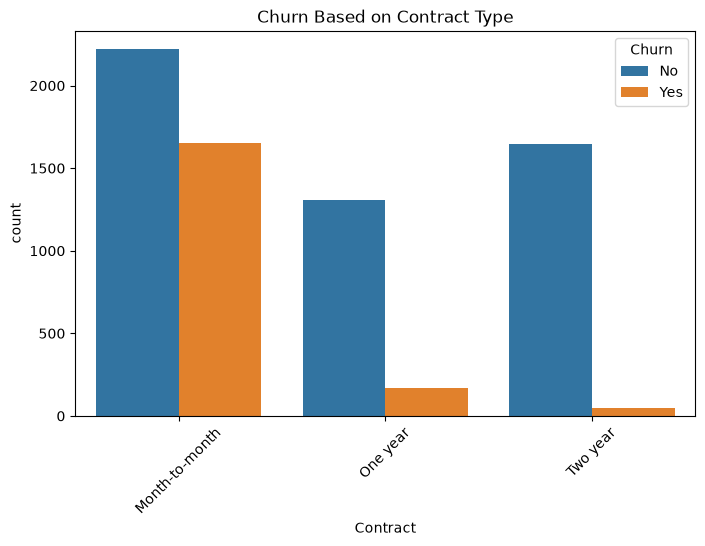

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title("Churn Based on Contract Type")

plt.xticks(rotation=45)

plt.show()

## Monthly Charges Analysis

This analysis shows the relationship between monthly charges and customer churn.

It helps identify whether pricing affects customer decisions.

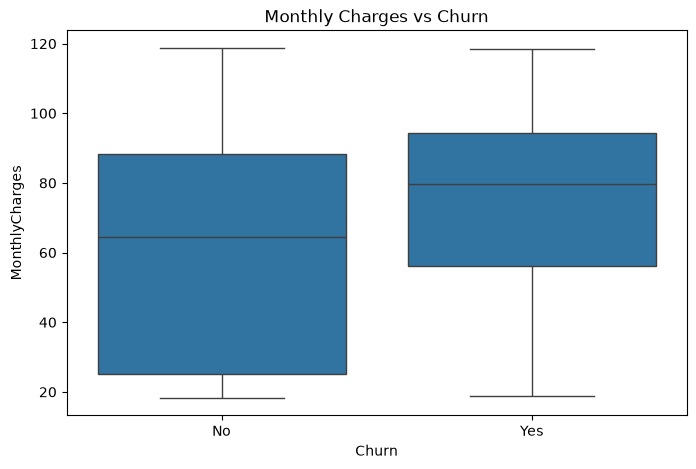

In [11]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title("Monthly Charges vs Churn")

plt.show()

## Customer Tenure Analysis

Customer tenure represents the duration of service usage.

This analysis helps identify whether new customers or long-term customers are more likely to churn.

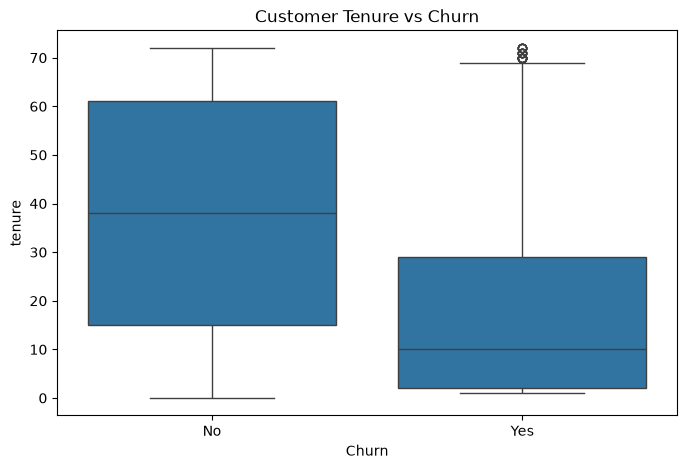

In [12]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title("Customer Tenure vs Churn")

plt.show()

## Feature Correlation Analysis

Correlation analysis helps identify relationships between numerical variables.

The heatmap displays the strength of relationships among different features.

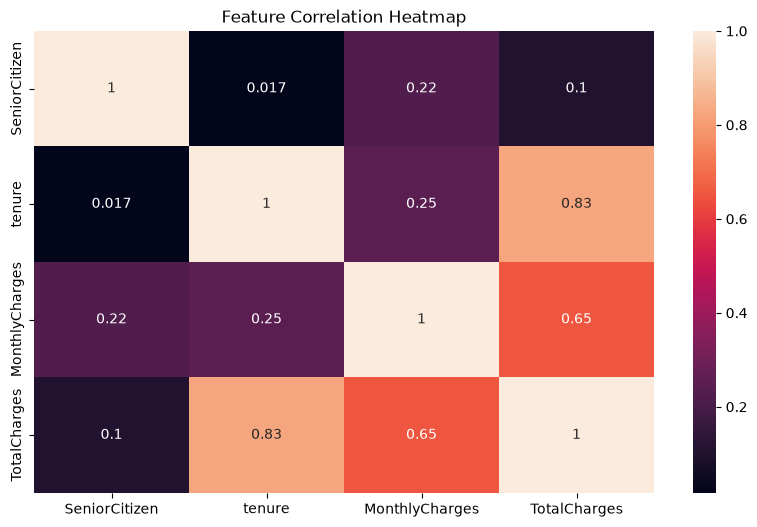

In [13]:
plt.figure(figsize=(10,6))

numeric_df = df.select_dtypes(include=['int64','float64'])

sns.heatmap(numeric_df.corr(), annot=True)

plt.title("Feature Correlation Heatmap")

plt.show()

## Feature Engineering

Feature engineering is the process of transforming raw customer data into meaningful features that can be used for machine learning models.

In this step, categorical variables are converted into numerical format and unnecessary columns are removed to improve model performance.

In [14]:
# Display all columns before feature engineering

df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Removing Unnecessary Features

CustomerID is only an identification field and does not provide useful information for predicting customer churn.

Therefore, it is removed from the dataset.

In [15]:
# Remove CustomerID column

df = df.drop('customerID', axis=1)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Encoding Categorical Variables

Machine learning algorithms require numerical input values.

Therefore, categorical features such as gender, contract type, payment method, and internet service are converted into numerical values using encoding techniques.

In [16]:
# Convert categorical variables into numerical format

df = pd.get_dummies(df, drop_first=True)

df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,True,False,True,False,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,True,False,True,False,True


## Updated Dataset Information

After feature engineering and encoding, the dataset structure is verified to ensure all features are in numerical format and ready for model training.

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7043 non-null   int64  
 1   tenure                                 7043 non-null   int64  
 2   MonthlyCharges                         7043 non-null   float64
 3   TotalCharges                           7043 non-null   float64
 4   gender_Male                            7043 non-null   bool   
 5   Partner_Yes                            7043 non-null   bool   
 6   Dependents_Yes                         7043 non-null   bool   
 7   PhoneService_Yes                       7043 non-null   bool   
 8   MultipleLines_No phone service         7043 non-null   bool   
 9   MultipleLines_Yes                      7043 non-null   bool   
 10  InternetService_Fiber optic            7043 non-null   bool   
 11  InternetService

## Feature and Target Separation

The dataset is divided into independent features (X) and target variable (y).

The target variable represents customer churn status which the machine learning model will predict.

In [19]:
# Separate input features and target variable

X = df.drop('Churn_Yes', axis=1)

y = df['Churn_Yes']

## Splitting Dataset into Training and Testing Data

The dataset is divided into training and testing sets.

Training data is used to train the machine learning model, while testing data is used to evaluate model performance.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (5634, 30)
Testing Data: (1409, 30)


# Machine Learning Model Building

Machine learning models are trained using customer data to predict whether a customer is likely to churn or continue using the service.

Different classification algorithms are implemented and compared to select the best performing model for the ChurnMind AI system.

## Logistic Regression

Logistic Regression is a classification algorithm used to predict binary outcomes.

In this project, it is used to predict whether a customer will churn or not.

In [22]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    max_iter=3000,
    solver='lbfgs'
)

log_model.fit(X_train, y_train)

log_prediction = log_model.predict(X_test)

## Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction accuracy and handle complex customer patterns.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)

## Model Performance Evaluation

The performance of machine learning models is evaluated using accuracy score, classification report, and confusion matrix.

In [24]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Logistic Regression Accuracy:")
print(accuracy_score(y_test, log_prediction))

print("\nRandom Forest Accuracy:")
print(accuracy_score(y_test, rf_prediction))

Logistic Regression Accuracy:
0.8218594748048261

Random Forest Accuracy:
0.7892122072391767


## Confusion Matrix

Confusion matrix is used to evaluate the correct and incorrect predictions made by the model.

It helps understand model performance in predicting churn and non-churn customers.

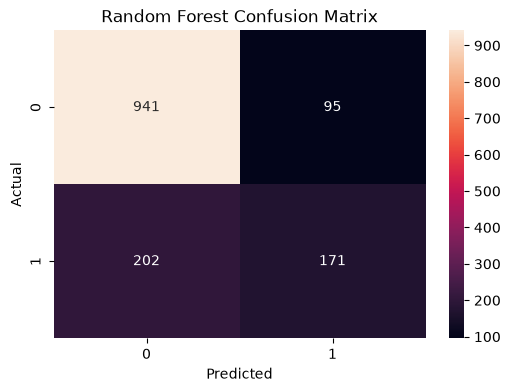

In [25]:
plt.figure(figsize=(6,4))

sns.heatmap(
    confusion_matrix(y_test, rf_prediction),
    annot=True,
    fmt='d'
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# Model Comparison

Different machine learning models are compared based on their accuracy score.

The best performing model will be selected for the final ChurnMind AI prediction system.

In [26]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test, log_prediction)

rf_accuracy = accuracy_score(y_test, rf_prediction)

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,0.821859
1,Random Forest,0.789212


## Accuracy Comparison of Models

This visualization compares the performance of different machine learning models.

The model with higher accuracy will be selected for customer churn prediction.

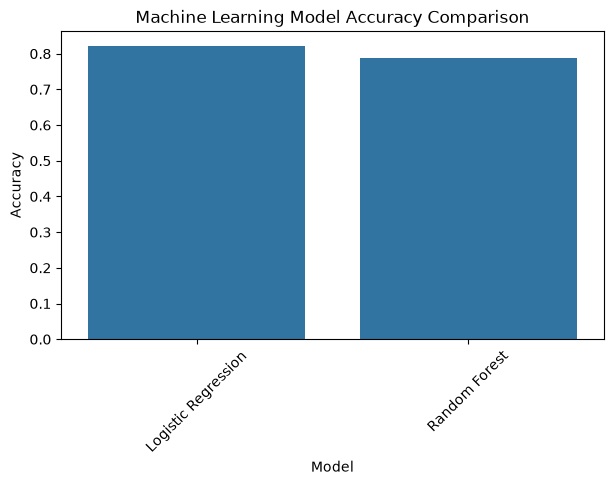

In [27]:
plt.figure(figsize=(7,4))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")

plt.xticks(rotation=45)

plt.show()

## Best Model Selection

Based on accuracy performance, the best machine learning model is selected.

This selected model will be integrated into the ChurnMind AI system for future customer predictions.

In [28]:
best_model = rf_model

print("Best Model Selected: Random Forest")

Best Model Selected: Random Forest


## Customer Churn Prediction Function

A prediction function is created to analyze new customer information.

The function takes customer details as input and predicts whether the customer is likely to churn or stay.

In [30]:
def predict_churn(customer_data):

    prediction = best_model.predict(customer_data)

    probability = best_model.predict_proba(customer_data)

    if prediction[0] == 1:
        result = "Customer is likely to churn"
    else:
        result = "Customer is likely to stay"

    return result, probability[0][1]

## Testing Churn Prediction System

The prediction system is tested using sample customer data to verify the working of the AI model.

In [31]:
sample_customer = X_test.iloc[0:1]

result, probability = predict_churn(sample_customer)

print("Prediction:", result)

print("Churn Probability:", probability)

Prediction: Customer is likely to churn
Churn Probability: 0.8


## Customer Risk Level Analysis

Based on churn probability, customers are categorized into different risk levels.

This helps businesses take preventive actions for customer retention.

In [32]:
def risk_level(probability):

    if probability >= 0.7:
        return "High Risk"

    elif probability >= 0.4:
        return "Medium Risk"

    else:
        return "Low Risk"

## Customer Retention Recommendation

The AI system provides recommendations based on customer churn risk level.

These suggestions help businesses improve customer retention.

In [33]:
def recommendation(level):

    if level == "High Risk":
        return "Offer discounts, loyalty benefits and personalized support."

    elif level == "Medium Risk":
        return "Engage customer with special offers and service improvements."

    else:
        return "Maintain good customer relationship."

# Saving Trained Model

The trained machine learning model is saved so that it can be reused in the ChurnMind AI Streamlit application without retraining every time.

The saved model will be used for real-time customer churn prediction.

In [34]:
import joblib

# Save the best trained model

joblib.dump(best_model, "churnmind_model.pkl")

print("Model saved successfully!")

Model saved successfully!


# Saving Feature Information

The model requires the same input features during prediction.

Therefore, the feature names are saved to maintain consistency between training data and future customer inputs.

In [35]:
joblib.dump(X.columns.tolist(), "feature_names.pkl")

print("Feature information saved successfully!")

Feature information saved successfully!


# Customer Insight Generation

This function generates meaningful insights from churn prediction results.

It converts machine learning output into understandable business recommendations.

In [36]:
def generate_insight(probability):

    if probability >= 0.7:
        return "High churn risk detected. Customer retention strategies should be applied."

    elif probability >= 0.4:
        return "Medium churn risk detected. Customer engagement can be improved."

    else:
        return "Customer is likely to stay. Maintain current service quality."

# Testing ChurnMind AI Logic

The complete prediction workflow is tested by combining prediction, probability calculation, risk analysis, and recommendation generation.

In [37]:
sample_data = X_test.iloc[0:1]

prediction = best_model.predict(sample_data)

probability = best_model.predict_proba(sample_data)[0][1]

if prediction[0] == 1:
    status = "Customer Likely to Churn"
else:
    status = "Customer Likely to Stay"

risk = risk_level(probability)

insight = generate_insight(probability)


print("Prediction:", status)
print("Churn Probability:", round(probability*100,2), "%")
print("Risk Level:", risk)
print("AI Insight:", insight)

Prediction: Customer Likely to Churn
Churn Probability: 80.0 %
Risk Level: High Risk
AI Insight: High churn risk detected. Customer retention strategies should be applied.


# Final Prediction Pipeline

This section combines machine learning prediction, probability calculation, risk classification, and AI-generated recommendations into a single workflow.

The final pipeline represents the core intelligence of the ChurnMind AI system.

In [1]:
def churnmind_prediction(customer):

    prediction = best_model.predict(customer)

    probability = best_model.predict_proba(customer)[0][1]

    if prediction[0] == 1:
        status = "Customer is likely to churn"
    else:
        status = "Customer is likely to stay"

    risk = risk_level(probability)

    suggestion = recommendation(risk)

    return {
        "Prediction": status,
        "Churn Probability": round(probability*100,2),
        "Risk Level": risk,
        "Recommendation": suggestion
    }

## Load Trained Churn Model

Loading the saved machine learning model for testing the ChurnMind AI agent.

In [2]:
import joblib

# Load trained model

model = joblib.load("churnmind_model.pkl")

print("Model loaded successfully")

Model loaded successfully


## Project Summary

ChurnMind AI is an intelligent customer analytics agent developed using machine learning techniques.

The project performs data preprocessing, exploratory data analysis, customer churn prediction and provides insights for customer retention.

It helps businesses identify customers who are likely to leave and supports better decision making using data-driven recommendations.

In [11]:
print("ChurnMind AI project completed successfully.")
print("Machine Learning model is ready for deployment using Streamlit.")

ChurnMind AI project completed successfully.
Machine Learning model is ready for deployment using Streamlit.


NameError: name 'fetures' is not defined